# MLB 2026 Utility Defender Value
## Defensive Value Visualizations
This notebook visualizes the results of a custom utility defender
evaluation model using 2026 Statcast Outs Above Average (OAA),
positional versatility, defensive workload, and playing-time
reliability adjustments.
The analysis evaluates 89 eligible MLB defenders across infield
and outfield positions, excluding catcher.
The composite score is a custom analytical metric and should not
be interpreted as an official MLB statistic or direct estimate
of runs saved.

In [1]:
# Step 43: Load final utility defender rankings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
# Set visualization style
sns.set_theme(style="whitegrid", context="notebook")
# Load final rankings
data_path = Path("../data/2026_utility_defender_rankings.csv")
df = pd.read_csv(data_path)
print("Total players:", len(df))
print("\nAvailable columns:")
print(df.columns.tolist())
display(df.head(10).round(3))

Total players: 89

Available columns:
['final_rank', 'player_id', 'player_name', 'adjusted_composite_score', 'total_innings', 'outs_above_average', 'oaa_per_1000_innings', 'versatility_score', 'meaningful_positions', 'demanding_position_share']


,final_rank,player_id,player_name,adjusted_composite_score,total_innings,outs_above_average,oaa_per_1000_innings,versatility_score,meaningful_positions,demanding_position_share
0,1,677649,Ezequiel Duran,76.934,1282.333,17.0,13.257,0.842,3,0.857
1,2,664702,Myles Straw,67.809,760.667,4.0,5.259,0.971,3,0.397
2,3,678391,Jorbit Vivas,65.513,747.333,4.0,5.352,1.000,2,1.000
3,4,823550,Sung-Mun Song,63.635,389.333,4.0,10.274,0.966,2,1.000
4,5,680757,Steven Kwan,63.475,1263.667,6.0,4.748,1.000,2,0.504
5,6,694728,Brice Matthews,63.192,531.000,6.0,11.299,0.787,3,0.731
6,7,681082,Bryson Stott,62.449,1321.000,9.0,6.813,0.853,2,1.000
7,8,663538,Nico Hoerner,62.264,1372.000,11.0,8.017,0.822,2,1.000
8,9,663968,Jake Mangum,61.410,986.333,-1.0,-1.014,0.921,3,0.499
9,10,805808,Kevin McGonigle,61.258,1319.667,-3.0,-2.273,1.000,2,1.000


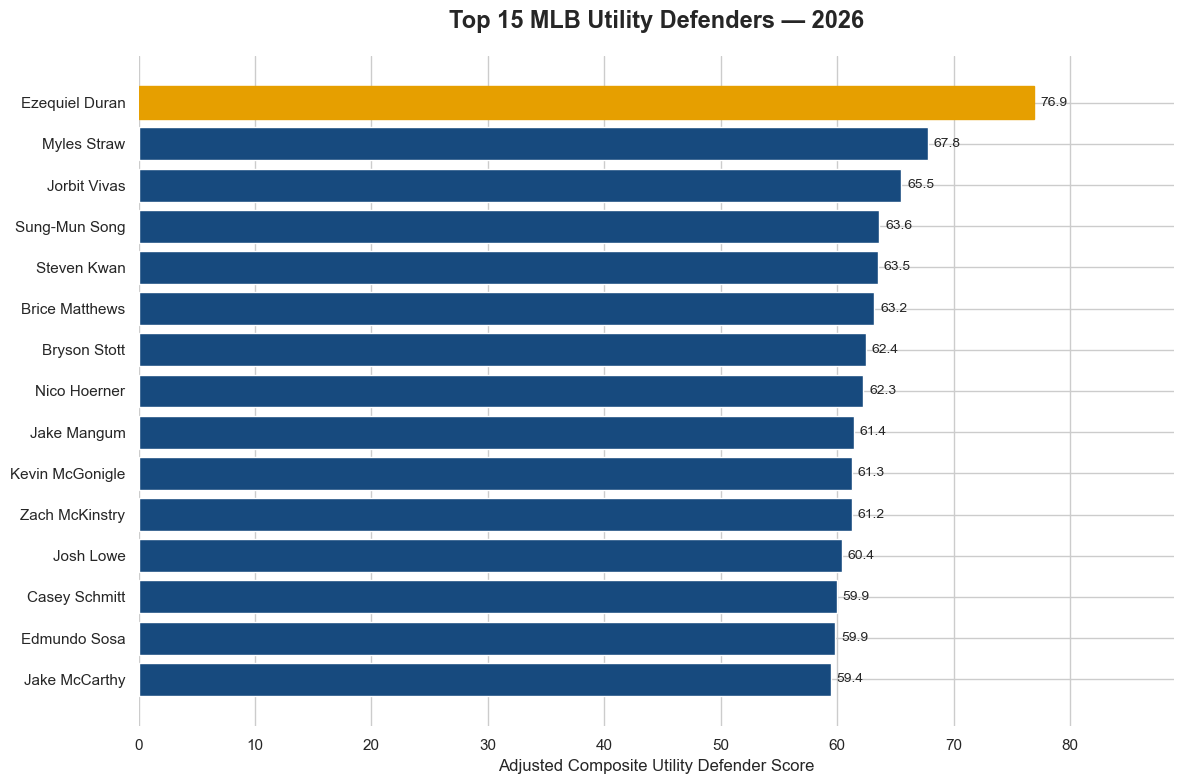

In [2]:
# Step 44: Visualize top 15 utility defenders
top15 = df.nsmallest(15, "final_rank").copy()
# Reverse order for horizontal bar chart
top15 = top15.sort_values("adjusted_composite_score")
fig, ax = plt.subplots(figsize=(12, 8))
bars = ax.barh(
    top15["player_name"],
    top15["adjusted_composite_score"],
    color="#174A7E",
    edgecolor="white"
)
# Highlight the highest-ranked defender
bars[-1].set_color("#E69F00")
# Add score labels
for bar in bars:
    width = bar.get_width()
    ax.text(
        width + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.1f}",
        va="center",
        fontsize=10
    )
ax.set_title(
    "Top 15 MLB Utility Defenders — 2026",
    fontsize=17,
    fontweight="bold",
    pad=20
)
ax.set_xlabel("Adjusted Composite Utility Defender Score")
ax.set_ylabel("")
ax.set_xlim(
    0,
    top15["adjusted_composite_score"].max() + 12
)
sns.despine(left=True, bottom=True)
plt.tight_layout()
# Save visualization
plt.savefig(
    "../visuals/top15_utility_defenders_2026.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

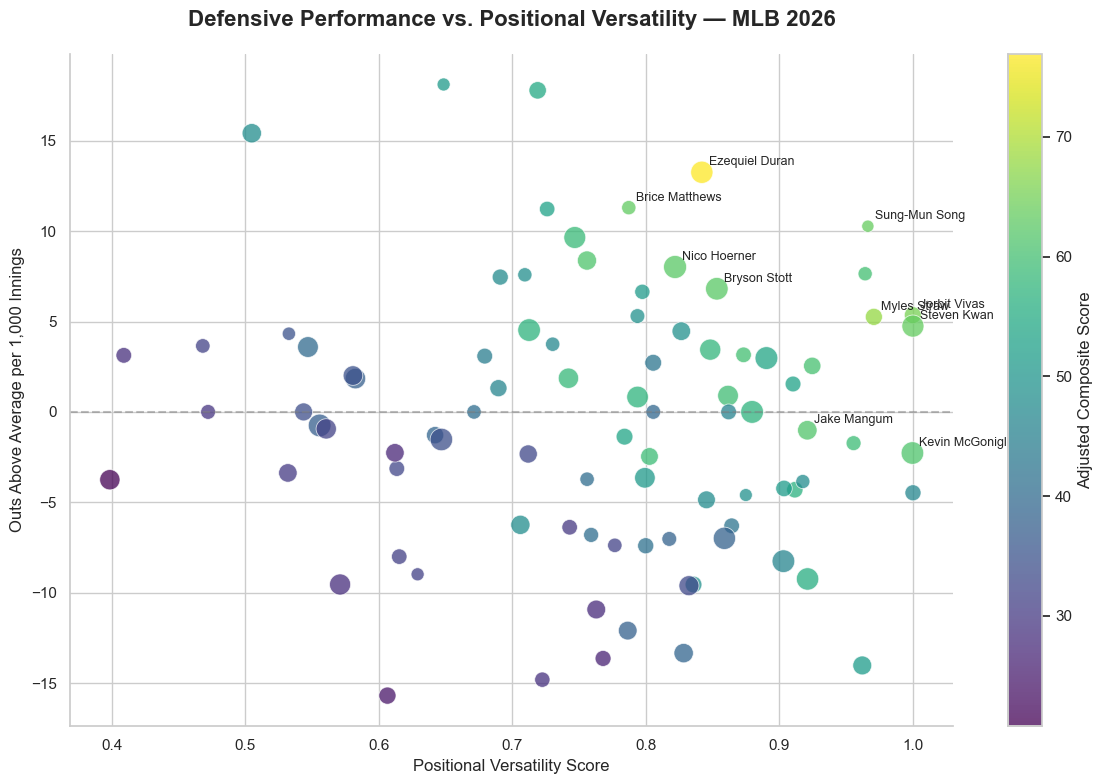

In [3]:
# Step 45: Defensive performance vs. positional versatility
fig, ax = plt.subplots(figsize=(12, 8))
scatter = ax.scatter(
    df["versatility_score"],
    df["oaa_per_1000_innings"],
    s=df["total_innings"] / 5,
    c=df["adjusted_composite_score"],
    cmap="viridis",
    alpha=0.75,
    edgecolors="white",
    linewidth=0.6
)
# Label the top 10 defenders
top10 = df.nsmallest(10, "final_rank")
for _, player in top10.iterrows():
    ax.annotate(
        player["player_name"],
        (
            player["versatility_score"],
            player["oaa_per_1000_innings"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Adjusted Composite Score")
ax.axhline(0, color="gray", linestyle="--", alpha=0.5)
ax.set_title(
    "Defensive Performance vs. Positional Versatility — MLB 2026",
    fontsize=16,
    fontweight="bold",
    pad=20
)
ax.set_xlabel("Positional Versatility Score")
ax.set_ylabel("Outs Above Average per 1,000 Innings")
sns.despine()
plt.tight_layout()
plt.savefig(
    "../visuals/defense_vs_versatility_2026.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

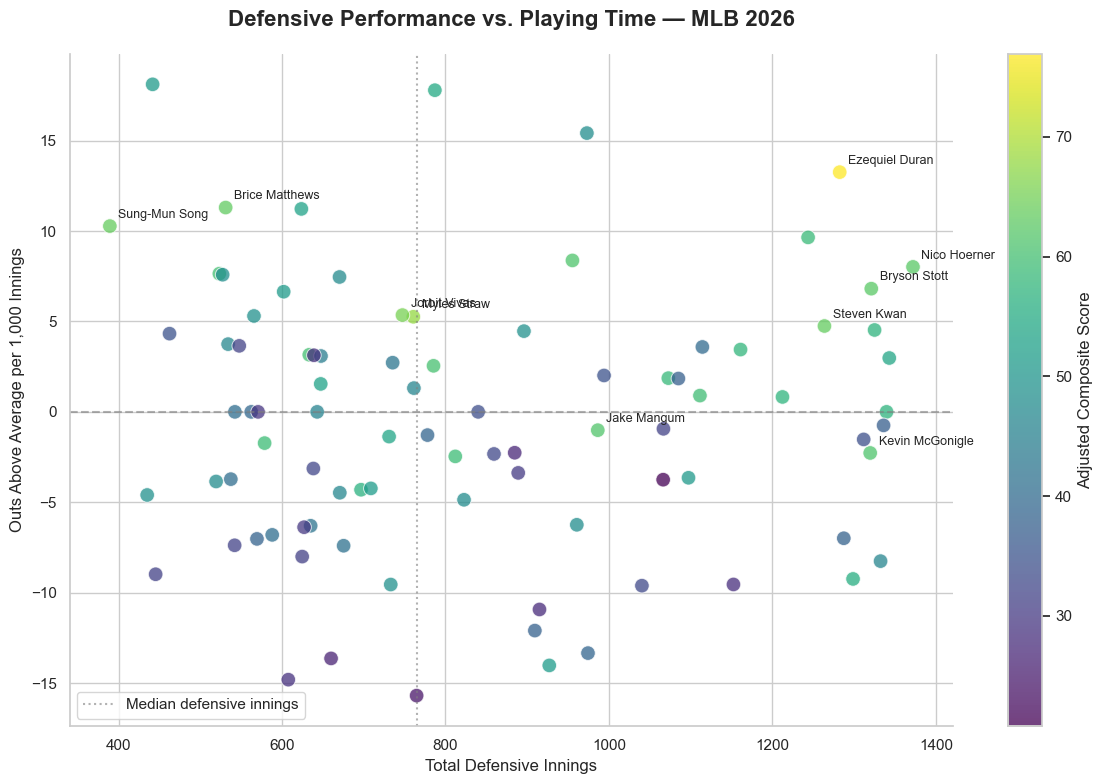

In [4]:
# Step 46: Defensive value vs. playing time
fig, ax = plt.subplots(figsize=(12, 8))
scatter = ax.scatter(
    df["total_innings"],
    df["oaa_per_1000_innings"],
    c=df["adjusted_composite_score"],
    cmap="viridis",
    s=110,
    alpha=0.75,
    edgecolors="white",
    linewidth=0.7
)
# Label top 10 ranked defenders
top10 = df.nsmallest(10, "final_rank")
for _, player in top10.iterrows():
    ax.annotate(
        player["player_name"],
        (
            player["total_innings"],
            player["oaa_per_1000_innings"]
        ),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=9
    )
# Reference lines
ax.axhline(
    0,
    color="gray",
    linestyle="--",
    alpha=0.6
)
ax.axvline(
    df["total_innings"].median(),
    color="gray",
    linestyle=":",
    alpha=0.6,
    label="Median defensive innings"
)
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Adjusted Composite Score")
ax.set_title(
    "Defensive Performance vs. Playing Time — MLB 2026",
    fontsize=16,
    fontweight="bold",
    pad=20
)
ax.set_xlabel("Total Defensive Innings")
ax.set_ylabel("Outs Above Average per 1,000 Innings")
ax.legend(loc="lower left")
sns.despine()
plt.tight_layout()
plt.savefig(
    "../visuals/defense_vs_playing_time_2026.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [5]:
# Step 47: Positional usage breakdown
import pandas as pd
import matplotlib.pyplot as plt
# Load position breakdown
positions = pd.read_csv("../data/2026_position_breakdown.csv")
print("Available columns:")
print(positions.columns.tolist())

display(positions.head())

Available columns:
['player_id', 'total_innings', 'player_name', '1B', '2B', '3B', 'CF', 'LF', 'RF', 'SS', 'calculated_total', 'innings_difference']


,player_id,total_innings,player_name,1B,2B,3B,CF,LF,RF,SS,calculated_total,innings_difference
0,663538,1372.000000,Nico Hoerner,0.000000,1019.666667,0.000000,0.0,0.0,0.0,352.333333,1372.000000,0.000000e+00
1,665487,1343.000000,Fernando Tatis Jr.,0.000000,413.000000,0.000000,0.0,0.0,930.0,0.000000,1343.000000,0.000000e+00
2,686797,1339.666667,Brooks Lee,0.000000,0.000000,939.666667,0.0,0.0,0.0,400.000000,1339.666667,2.273737e-13
3,666182,1336.000000,Bo Bichette,0.000000,1.000000,943.666667,0.0,0.0,0.0,391.333333,1336.000000,0.000000e+00
4,664761,1332.333333,Alec Bohm,424.666667,0.000000,907.666667,0.0,0.0,0.0,0.000000,1332.333333,0.000000e+00


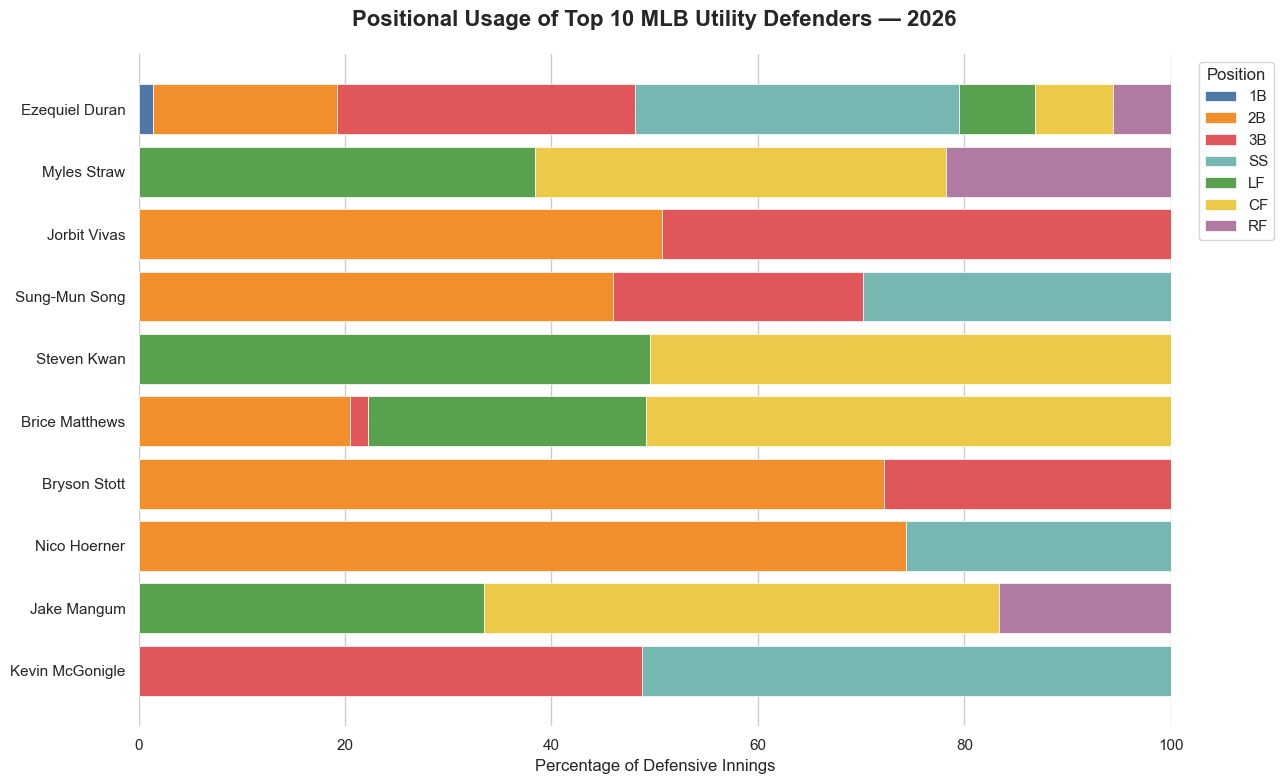

In [6]:
# Step 48: Top 10 positional usage breakdown

import numpy as np
import matplotlib.pyplot as plt

# Identify the top 10 defenders
top10 = df.nsmallest(10, "final_rank")[
    ["player_id", "player_name", "final_rank"]
].copy()

# Merge with positional innings
usage = top10.merge(
    positions,
    on="player_id",
    how="left",
    suffixes=("", "_position")
)

# Seven defensive positions (excluding catcher)
position_cols = ["1B", "2B", "3B", "SS", "LF", "CF", "RF"]

# Convert innings into percentages
position_innings = usage[position_cols].fillna(0)

usage_pct = position_innings.div(
    position_innings.sum(axis=1).replace(0, np.nan),
    axis=0
).fillna(0) * 100

# Create horizontal stacked bar chart
fig, ax = plt.subplots(figsize=(13, 8))

colors = [
    "#4E79A7", "#F28E2B", "#E15759",
    "#76B7B2", "#59A14F", "#EDC948", "#B07AA1"
]

left = np.zeros(len(usage))

for pos, color in zip(position_cols, colors):
    ax.barh(
        usage["player_name"],
        usage_pct[pos],
        left=left,
        label=pos,
        color=color,
        edgecolor="white",
        linewidth=0.5
    )

    left += usage_pct[pos].to_numpy()

ax.invert_yaxis()

ax.set_xlim(0, 100)
ax.set_xlabel("Percentage of Defensive Innings")
ax.set_ylabel("")

ax.set_title(
    "Positional Usage of Top 10 MLB Utility Defenders — 2026",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.legend(
    title="Position",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

sns.despine(left=True, bottom=True)
plt.tight_layout()

plt.savefig(
    "../visuals/positional_usage_top10_2026.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

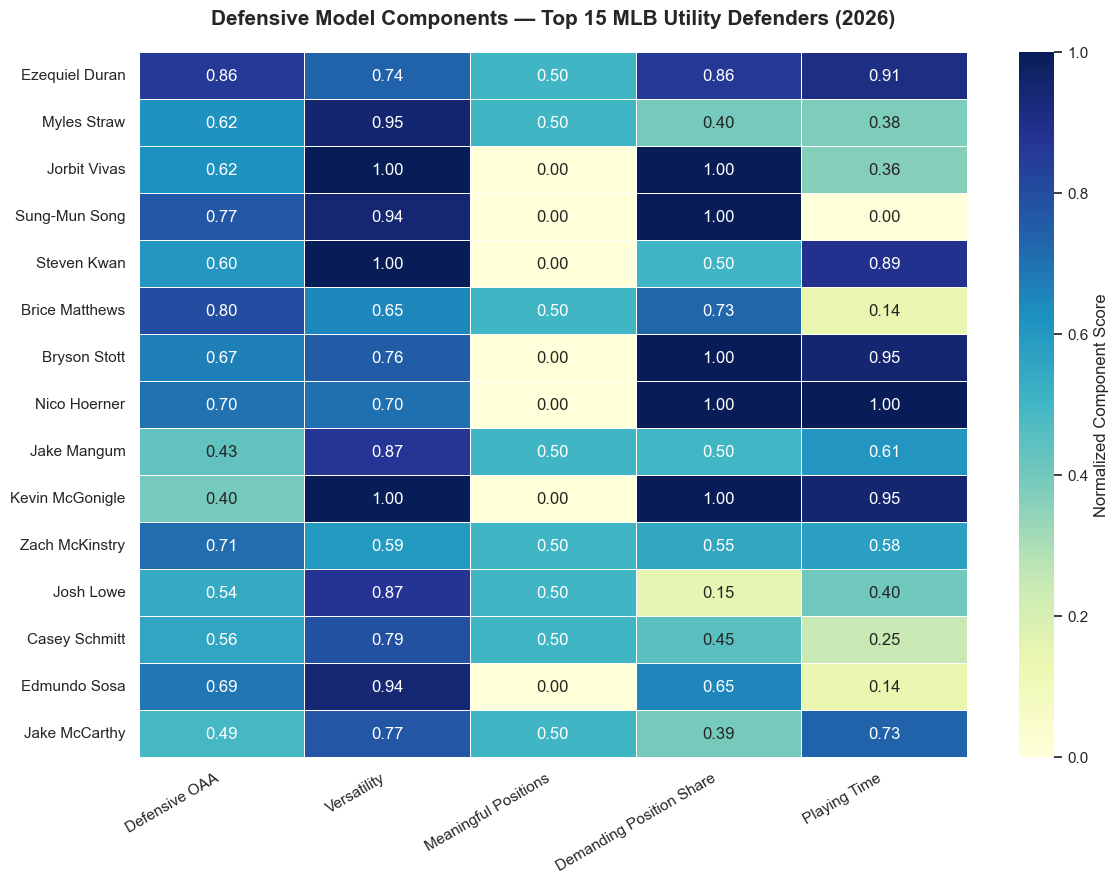

In [7]:
# Step 49: Defensive model component heatmap
import seaborn as sns
import matplotlib.pyplot as plt
components = [
    "oaa_per_1000_innings",
    "versatility_score",
    "meaningful_positions",
    "demanding_position_share",
    "total_innings"
]
# Top 15 ranked players
top15 = df.nsmallest(15, "final_rank").copy()
# Normalize each component using the full eligible player pool
normalized = df[components].copy()
for col in components:
    minimum = normalized[col].min()
    maximum = normalized[col].max()
    if maximum > minimum:
        normalized[col] = (
            (normalized[col] - minimum) /
            (maximum - minimum)
        )
    else:
        normalized[col] = 0.0
# Select normalized values for top 15
heatmap_data = normalized.loc[top15.index].copy()
heatmap_data.index = top15["player_name"].values
heatmap_data.columns = [
    "Defensive OAA",
    "Versatility",
    "Meaningful Positions",
    "Demanding Position Share",
    "Playing Time"
]
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5,
    vmin=0,
    vmax=1,
    cbar_kws={"label": "Normalized Component Score"},
    ax=ax
)
ax.set_title(
    "Defensive Model Components — Top 15 MLB Utility Defenders (2026)",
    fontsize=15,
    fontweight="bold",
    pad=20
)
ax.set_xlabel("")
ax.set_ylabel("")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(
    "../visuals/defensive_component_heatmap_2026.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [8]:
# Step 50: Inspect scoring component distributions

components = [
    "oaa_per_1000_innings",
    "versatility_score",
    "meaningful_positions",
    "demanding_position_share",
    "total_innings"
]

print("Component distributions:")
display(df[components].describe().round(3))

print("\nMeaningful positions distribution:")
print(df["meaningful_positions"].value_counts().sort_index())

print("\nTop 15 raw scoring components:")
display(
    df.nsmallest(15, "final_rank")[
        ["player_name", "final_rank"] + components
    ].round(3)
)

Component distributions:


,oaa_per_1000_innings,versatility_score,meaningful_positions,demanding_position_share,total_innings
count,89.000,89.000,89.000,89.000,89.000
mean,-0.430,0.761,2.270,0.635,840.461
std,7.251,0.145,0.471,0.352,280.840
min,-15.693,0.399,2.000,0.000,389.333
25%,-4.862,0.671,2.000,0.394,623.667
50%,0.000,0.786,2.000,0.681,764.667
75%,3.745,0.862,3.000,0.993,1066.667
max,18.113,1.000,4.000,1.000,1372.000



Meaningful positions distribution:
meaningful_positions
2    66
3    22
4     1
Name: count, dtype: int64

Top 15 raw scoring components:


,player_name,final_rank,oaa_per_1000_innings,versatility_score,meaningful_positions,demanding_position_share,total_innings
0,Ezequiel Duran,1,13.257,0.842,3,0.857,1282.333
1,Myles Straw,2,5.259,0.971,3,0.397,760.667
2,Jorbit Vivas,3,5.352,1.000,2,1.000,747.333
3,Sung-Mun Song,4,10.274,0.966,2,1.000,389.333
4,Steven Kwan,5,4.748,1.000,2,0.504,1263.667
5,Brice Matthews,6,11.299,0.787,3,0.731,531.000
6,Bryson Stott,7,6.813,0.853,2,1.000,1321.000
7,Nico Hoerner,8,8.017,0.822,2,1.000,1372.000
8,Jake Mangum,9,-1.014,0.921,3,0.499,986.333
9,Kevin McGonigle,10,-2.273,1.000,2,1.000,1319.667


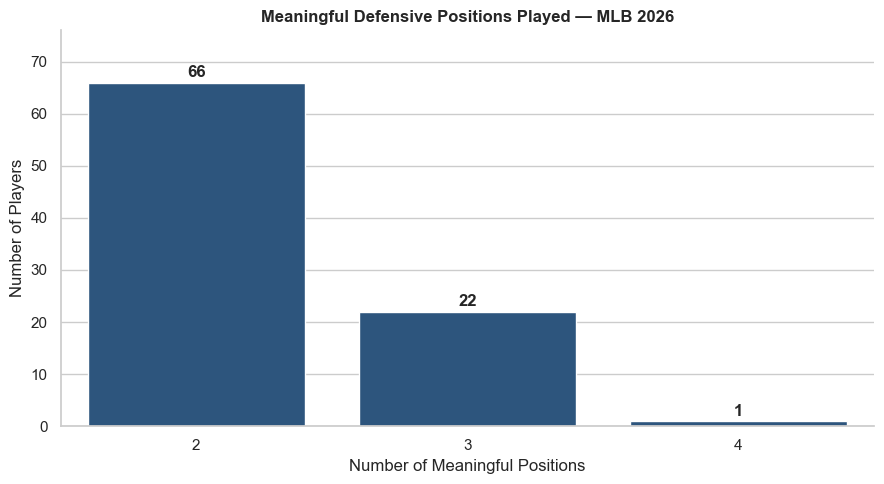

In [9]:
# Step 51: Meaningful positional versatility distribution

import matplotlib.pyplot as plt
import seaborn as sns

counts = (
    df["meaningful_positions"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=counts.index,
    y=counts.values,
    color="#20558A"
)

for i, value in enumerate(counts.values):
    ax.text(
        i,
        value + 1,
        str(value),
        ha="center",
        fontweight="bold"
    )

plt.title(
    "Meaningful Defensive Positions Played — MLB 2026",
    fontweight="bold"
)

plt.xlabel("Number of Meaningful Positions")
plt.ylabel("Number of Players")
plt.ylim(0, counts.max() + 10)

sns.despine()
plt.tight_layout()

plt.savefig(
    "../visuals/meaningful_positions_distribution_2026.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
# Step 52: Compare alternative model weights

import pandas as pd
from sklearn.preprocessing import MinMaxScaler

components = [
    "oaa_per_1000_innings",
    "versatility_score",
    "meaningful_positions",
    "demanding_position_share",
    "total_innings"
]

scenarios = {
    "balanced": [0.30, 0.35, 0.20, 0.10, 0.05],
    "defense_first": [0.50, 0.20, 0.15, 0.10, 0.05],
    "versatility_first": [0.20, 0.50, 0.15, 0.10, 0.05]
}

normalized = pd.DataFrame(
    MinMaxScaler().fit_transform(df[components]),
    columns=components,
    index=df.index
)

sensitivity = df[["player_name", "final_rank"]].copy()

for scenario, weights in scenarios.items():
    sensitivity[f"{scenario}_score"] = (
        normalized.mul(weights).sum(axis=1) * 100
    )

    sensitivity[f"{scenario}_rank"] = (
        sensitivity[f"{scenario}_score"]
        .rank(ascending=False, method="min")
        .astype(int)
    )

display(
    sensitivity.sort_values("final_rank").head(20)
)

,player_name,final_rank,balanced_score,balanced_rank,defense_first_score,defense_first_rank,versatility_first_score,versatility_first_rank
0,Ezequiel Duran,1,74.598400,1,78.168824,1,74.591522,1
1,Myles Straw,2,67.751404,2,63.377345,8,73.323020,3
2,Jorbit Vivas,3,65.488944,4,62.943227,11,74.259970,2
3,Sung-Mun Song,4,66.076906,3,67.281956,4,72.552990,5
4,Steven Kwan,5,62.626542,6,59.720869,15,71.578777,6
5,Brice Matthews,6,64.596093,5,68.372931,3,63.803723,16
6,Bryson Stott,7,61.164642,9,63.142812,10,65.843846,11
7,Nico Hoerner,8,60.672443,11,64.143423,6,64.215123,13
8,Jake Mangum,9,61.450794,8,54.608649,24,67.635102,8
9,Kevin McGonigle,10,61.618385,7,54.567980,25,72.638406,4


In [11]:
# Step 53: Analyze ranking stability

rank_columns = [
    "balanced_rank",
    "defense_first_rank",
    "versatility_first_rank"
]

sensitivity["best_rank"] = sensitivity[rank_columns].min(axis=1)
sensitivity["worst_rank"] = sensitivity[rank_columns].max(axis=1)

sensitivity["rank_range"] = (
    sensitivity["worst_rank"] -
    sensitivity["best_rank"]
)

sensitivity["average_rank"] = (
    sensitivity[rank_columns].mean(axis=1)
)

# Compare top 20 players from original rankings
top20_stability = (
    sensitivity
    .sort_values("final_rank")
    .head(20)
)

display(
    top20_stability[
        [
            "player_name",
            "final_rank",
            "balanced_rank",
            "defense_first_rank",
            "versatility_first_rank",
            "rank_range",
            "average_rank"
        ]
    ].round(2)
)

print("\nAverage rank movement across all players:")
print(round(sensitivity["rank_range"].mean(), 2))

print("\nPlayers remaining top 10 in all three scenarios:")
stable_top10 = sensitivity[
    (sensitivity[rank_columns] <= 10).all(axis=1)
]

display(
    stable_top10[
        ["player_name"] + rank_columns
    ].sort_values("balanced_rank")
)

,player_name,final_rank,balanced_rank,defense_first_rank,versatility_first_rank,rank_range,average_rank
0,Ezequiel Duran,1,1,1,1,0,1.00
1,Myles Straw,2,2,8,3,6,4.33
2,Jorbit Vivas,3,4,11,2,9,5.67
3,Sung-Mun Song,4,3,4,5,2,4.00
4,Steven Kwan,5,6,15,6,9,9.00
5,Brice Matthews,6,5,3,16,13,8.00
6,Bryson Stott,7,9,10,11,2,10.00
7,Nico Hoerner,8,11,6,13,7,10.00
8,Jake Mangum,9,8,24,8,16,13.33
9,Kevin McGonigle,10,7,25,4,21,12.00



Average rank movement across all players:
15.8

Players remaining top 10 in all three scenarios:


,player_name,balanced_rank,defense_first_rank,versatility_first_rank
0,Ezequiel Duran,1,1,1
1,Myles Straw,2,8,3
3,Sung-Mun Song,3,4,5


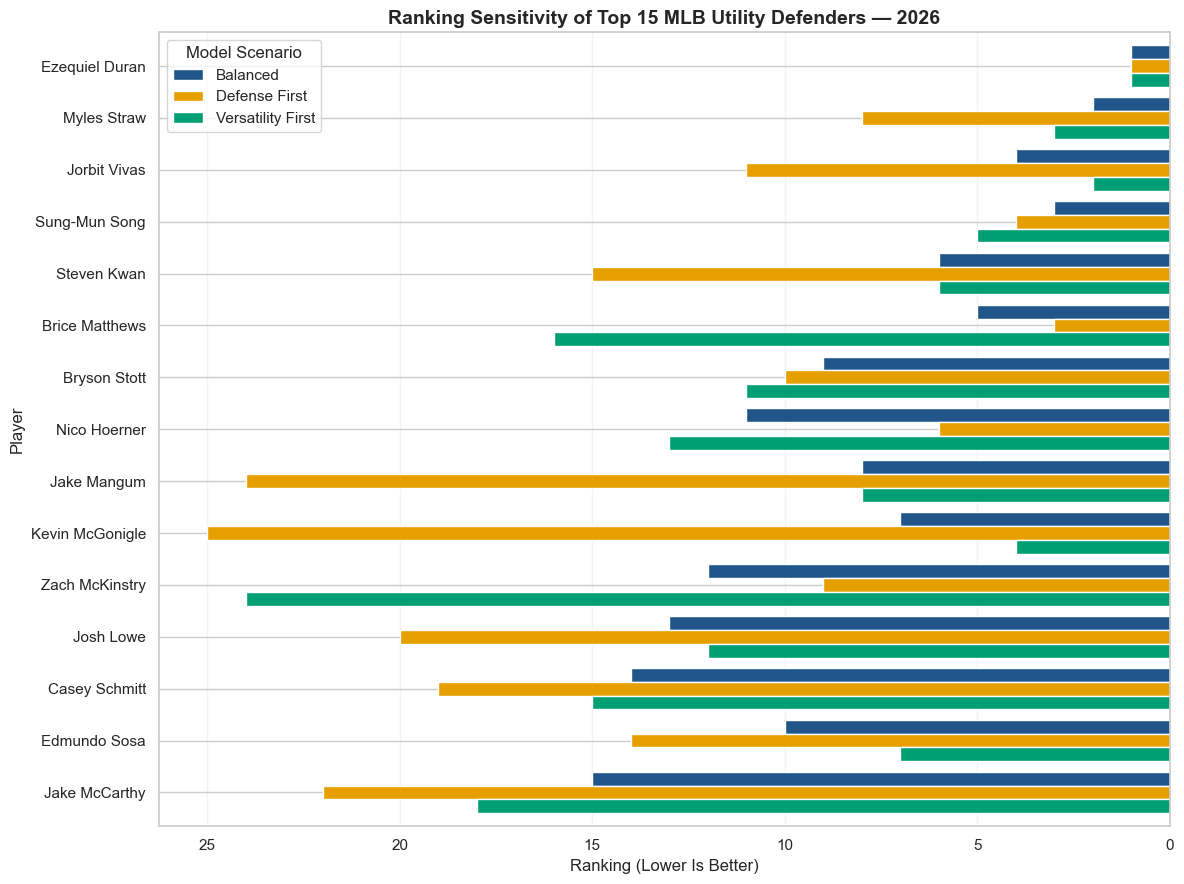

In [12]:
# Step 54: Visualize ranking stability across scenarios

import matplotlib.pyplot as plt
import pandas as pd

top15 = (
    sensitivity
    .sort_values("final_rank")
    .head(15)
    .copy()
)

plot_data = top15.set_index("player_name")[
    [
        "balanced_rank",
        "defense_first_rank",
        "versatility_first_rank"
    ]
]

ax = plot_data.plot(
    kind="barh",
    figsize=(12, 9),
    width=0.8,
    color=["#20558A", "#E69F00", "#009E73"]
)

ax.invert_yaxis()
ax.invert_xaxis()

plt.title(
    "Ranking Sensitivity of Top 15 MLB Utility Defenders — 2026",
    fontweight="bold",
    fontsize=14
)

plt.xlabel("Ranking (Lower Is Better)")
plt.ylabel("Player")

plt.legend(
    ["Balanced", "Defense First", "Versatility First"],
    title="Model Scenario"
)

plt.grid(axis="x", alpha=0.25)
plt.tight_layout()

plt.savefig(
    "../visuals/ranking_sensitivity_2026.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [13]:
# Step 55: Identify most stable and unstable rankings

scenario_cols = [
    "balanced_rank",
    "defense_first_rank",
    "versatility_first_rank"
]

stability = sensitivity.copy()

stability["rank_range"] = (
    stability[scenario_cols].max(axis=1)
    - stability[scenario_cols].min(axis=1)
)

print("MOST STABLE PLAYERS")
display(
    stability.sort_values(
        ["rank_range", "final_rank"]
    )[
        ["player_name", "final_rank", "rank_range"]
        + scenario_cols
    ].head(10)
)

print("\nMOST WEIGHT-SENSITIVE PLAYERS")
display(
    stability.sort_values(
        "rank_range", ascending=False
    )[
        ["player_name", "final_rank", "rank_range"]
        + scenario_cols
    ].head(10)
)

MOST STABLE PLAYERS


,player_name,final_rank,rank_range,balanced_rank,defense_first_rank,versatility_first_rank
0,Ezequiel Duran,1,0,1,1,1
58,Mickey Moniak,59,1,60,61,60
83,Nick Gonzales,84,1,81,80,81
3,Sung-Mun Song,4,2,3,4,5
6,Bryson Stott,7,2,9,10,11
77,Ben Williamson,78,2,77,78,76
19,Nasim Nuñez,20,3,21,18,20
72,Luis Rengifo,73,3,73,72,75
20,Kody Clemens,21,4,22,26,25
38,Dylan Crews,39,4,39,36,40



MOST WEIGHT-SENSITIVE PLAYERS


,player_name,final_rank,rank_range,balanced_rank,defense_first_rank,versatility_first_rank
40,Joey Ortiz,41,52,47,12,64
30,Vaughn Grissom,31,47,32,64,17
32,Isiah Kiner-Falefa,33,42,26,2,44
25,Jonny DeLuca,26,37,27,5,42
66,Pedro Ramírez,67,36,67,43,79
46,Ryan O'Hearn,47,35,48,63,28
75,Alika Williams,76,34,74,52,86
24,Luke Keaschall,25,32,19,42,10
59,J.P. Crawford,60,30,56,77,47
82,Nicky Lopez,83,29,83,59,88


In [14]:
# Step 56: Export ranking sensitivity analysis

from pathlib import Path

output_dir = Path("../data")
output_dir.mkdir(parents=True, exist_ok=True)

export_cols = [
    "player_name",
    "final_rank",
    "balanced_rank",
    "defense_first_rank",
    "versatility_first_rank",
    "rank_range"
]

stability_export = stability[export_cols].copy()

stability_export = stability_export.sort_values(
    "final_rank"
)

output_path = output_dir / "2026_ranking_sensitivity.csv"

stability_export.to_csv(output_path, index=False)

print("Ranking sensitivity analysis exported!")
print("File:", output_path)
print("Players analyzed:", len(stability_export))

display(stability_export.head(10))

Ranking sensitivity analysis exported!
File: ../data/2026_ranking_sensitivity.csv
Players analyzed: 89


,player_name,final_rank,balanced_rank,defense_first_rank,versatility_first_rank,rank_range
0,Ezequiel Duran,1,1,1,1,0
1,Myles Straw,2,2,8,3,6
2,Jorbit Vivas,3,4,11,2,9
3,Sung-Mun Song,4,3,4,5,2
4,Steven Kwan,5,6,15,6,9
5,Brice Matthews,6,5,3,16,13
6,Bryson Stott,7,9,10,11,2
7,Nico Hoerner,8,11,6,13,7
8,Jake Mangum,9,8,24,8,16
9,Kevin McGonigle,10,7,25,4,21


In [15]:
# Step 57: Build top-five defensive player profiles

import pandas as pd

rankings = pd.read_csv(
    "../data/2026_utility_defender_rankings.csv"
)

sensitivity = pd.read_csv(
    "../data/2026_ranking_sensitivity.csv"
)

top_five = rankings.nsmallest(
    5, "final_rank"
).copy()

# Add ranking sensitivity information
top_five = top_five.merge(
    sensitivity[
        [
            "player_name",
            "balanced_rank",
            "defense_first_rank",
            "versatility_first_rank",
            "rank_range"
        ]
    ],
    on="player_name",
    how="left",
    validate="one_to_one"
)

print("Top five defensive scouting profiles:")
print("Players:", len(top_five))

display(top_five.T)

Top five defensive scouting profiles:
Players: 5


,0,1,2,3,4
final_rank,1,2,3,4,5
player_id,677649,664702,678391,823550,680757
player_name,Ezequiel Duran,Myles Straw,Jorbit Vivas,Sung-Mun Song,Steven Kwan
adjusted_composite_score,76.934022,67.809186,65.51343,63.63542,63.474741
total_innings,1282.333333,760.666667,747.333333,389.333333,1263.666667
outs_above_average,17.0,4.0,4.0,4.0,6.0
oaa_per_1000_innings,13.257083,5.258545,5.352364,10.273973,4.748088
versatility_score,0.841938,0.970706,0.999853,0.966218,0.999952
meaningful_positions,3,3,2,2,2
demanding_position_share,0.856512,0.397458,1.0,1.0,0.504089


In [16]:
# Step 58: Merge positional usage into top-five profiles

positions = pd.read_csv(
    "../data/2026_position_breakdown.csv"
)

position_cols = [
    "player_id", "1B", "2B", "3B",
    "SS", "LF", "CF", "RF"
]

top_five_profiles = top_five.merge(
    positions[position_cols],
    on="player_id",
    how="left",
    validate="one_to_one"
)

print("Top-five profiles with positional innings:")

display(
    top_five_profiles[
        [
            "player_name",
            "final_rank",
            "total_innings",
            "outs_above_average",
            "1B", "2B", "3B",
            "SS", "LF", "CF", "RF"
        ]
    ].round(1)
)

Top-five profiles with positional innings:


,player_name,final_rank,total_innings,outs_above_average,1B,2B,3B,SS,LF,CF,RF
0,Ezequiel Duran,1,1282.3,17.0,18.0,229.0,369.3,403.0,94.0,97.0,72.0
1,Myles Straw,2,760.7,4.0,0.0,0.0,0.0,0.0,292.3,302.3,166.0
2,Jorbit Vivas,3,747.3,4.0,0.0,379.0,368.3,0.0,0.0,0.0,0.0
3,Sung-Mun Song,4,389.3,4.0,0.0,179.0,94.3,116.0,0.0,0.0,0.0
4,Steven Kwan,5,1263.7,6.0,0.0,0.0,0.0,0.0,626.7,637.0,0.0


In [17]:
# Step 59: Validate positional innings

position_cols = [
    "1B", "2B", "3B", "SS", "LF", "CF", "RF"
]

top_five_profiles["position_innings_sum"] = (
    top_five_profiles[position_cols].sum(axis=1)
)

top_five_profiles["innings_difference"] = (
    top_five_profiles["total_innings"]
    - top_five_profiles["position_innings_sum"]
)

validation = top_five_profiles[
    [
        "player_name",
        "total_innings",
        "position_innings_sum",
        "innings_difference"
    ]
].copy()

validation["validation_status"] = (
    validation["innings_difference"].abs()
    .le(0.01)
    .map({True: "PASS", False: "REVIEW"})
)

display(validation.round(3))

,player_name,total_innings,position_innings_sum,innings_difference,validation_status
0,Ezequiel Duran,1282.333,1282.333,0.0,PASS
1,Myles Straw,760.667,760.667,0.0,PASS
2,Jorbit Vivas,747.333,747.333,0.0,PASS
3,Sung-Mun Song,389.333,389.333,0.0,PASS
4,Steven Kwan,1263.667,1263.667,0.0,PASS


In [18]:

# Step 60: Calculate positional usage percentages

position_cols = [
    "1B", "2B", "3B", "SS", "LF", "CF", "RF"
]

usage_pct = top_five_profiles[
    ["player_name", "final_rank", "total_innings"]
].copy()

for pos in position_cols:
    usage_pct[f"{pos}_pct"] = (
        top_five_profiles[pos]
        / top_five_profiles["total_innings"]
        * 100
    )

# Identify primary and secondary positions
top_five_profiles["primary_position"] = (
    top_five_profiles[position_cols].idxmax(axis=1)
)

top_five_profiles["secondary_position"] = (
    top_five_profiles[position_cols]
    .apply(lambda row: row.nlargest(2).index[-1], axis=1)
)

# Display positional percentages
display(usage_pct.round(1))

print("\nPrimary and secondary positions:")
display(
    top_five_profiles[
        ["player_name", "primary_position", "secondary_position"]
    ]
)


,player_name,final_rank,total_innings,1B_pct,2B_pct,3B_pct,SS_pct,LF_pct,CF_pct,RF_pct
0,Ezequiel Duran,1,1282.3,1.4,17.9,28.8,31.4,7.3,7.6,5.6
1,Myles Straw,2,760.7,0.0,0.0,0.0,0.0,38.4,39.7,21.8
2,Jorbit Vivas,3,747.3,0.0,50.7,49.3,0.0,0.0,0.0,0.0
3,Sung-Mun Song,4,389.3,0.0,46.0,24.2,29.8,0.0,0.0,0.0
4,Steven Kwan,5,1263.7,0.0,0.0,0.0,0.0,49.6,50.4,0.0



Primary and secondary positions:


,player_name,primary_position,secondary_position
0,Ezequiel Duran,SS,3B
1,Myles Straw,CF,LF
2,Jorbit Vivas,2B,3B
3,Sung-Mun Song,2B,SS
4,Steven Kwan,CF,LF


In [19]:

# Step 61: Build top-five scouting report table

scouting_columns = [
    "final_rank",
    "player_name",
    "adjusted_composite_score",
    "total_innings",
    "outs_above_average",
    "oaa_per_1000_innings",
    "versatility_score",
    "meaningful_positions",
    "primary_position",
    "secondary_position",
    "balanced_rank",
    "defense_first_rank",
    "versatility_first_rank",
    "rank_range"
]

scouting_reports = (
    top_five_profiles[scouting_columns]
    .copy()
    .sort_values("final_rank")
    .reset_index(drop=True)
)

display(scouting_reports.T.round(3))

# Export scouting report data
scouting_reports.to_csv(
    "../data/2026_top5_defensive_scouting_profiles.csv",
    index=False
)

print("Top-five scouting profiles exported successfully!")
print("Players:", len(scouting_reports))


,0,1,2,3,4
final_rank,1,2,3,4,5
player_name,Ezequiel Duran,Myles Straw,Jorbit Vivas,Sung-Mun Song,Steven Kwan
adjusted_composite_score,76.934022,67.809186,65.51343,63.63542,63.474741
total_innings,1282.333333,760.666667,747.333333,389.333333,1263.666667
outs_above_average,17.0,4.0,4.0,4.0,6.0
oaa_per_1000_innings,13.257083,5.258545,5.352364,10.273973,4.748088
versatility_score,0.841938,0.970706,0.999853,0.966218,0.999952
meaningful_positions,3,3,2,2,2
primary_position,SS,CF,2B,2B,CF
secondary_position,3B,LF,3B,SS,LF


Top-five scouting profiles exported successfully!
Players: 5


In [20]:

# Step 62: Generate individual defensive scouting reports

from pathlib import Path

report_dir = Path("../reports")
report_dir.mkdir(parents=True, exist_ok=True)

def generate_scouting_report(player):
    name = player["player_name"]
    rank = int(player["final_rank"])
    score = player["adjusted_composite_score"]
    innings = player["total_innings"]
    oaa = player["outs_above_average"]
    oaa_rate = player["oaa_per_1000_innings"]
    versatility = player["versatility_score"]
    positions = int(player["meaningful_positions"])
    primary = player["primary_position"]
    secondary = player["secondary_position"]
    rank_range = int(player["rank_range"])

    if oaa_rate >= 10:
        defense = "Strong positive defensive performance"
    elif oaa_rate >= 5:
        defense = "Above-average defensive performance"
    elif oaa_rate >= 0:
        defense = "Modestly positive defensive performance"
    else:
        defense = "Below-average defensive performance"

    if rank_range <= 3:
        stability = "Highly stable across model scenarios"
    elif rank_range <= 10:
        stability = "Moderately stable across model scenarios"
    else:
        stability = "Sensitive to model weighting assumptions"

    report = f"""# {name} — 2026 Defensive Scouting Report

## Overall Evaluation
- Final utility defender rank: #{rank}
- Adjusted composite score: {score:.2f}/100
- Defensive innings: {innings:.1f}

## Defensive Performance
- Outs Above Average: {oaa:+.0f}
- OAA per 1,000 innings: {oaa_rate:+.2f}
- Assessment: {defense}

## Positional Versatility
- Primary position: {primary}
- Secondary position: {secondary}
- Meaningful positions played: {positions}
- Versatility score: {versatility:.3f}

## Model Robustness
- Ranking range across scenarios: {rank_range}
- Assessment: {stability}

## Scouting Interpretation
{name} ranks #{rank} in the custom 2026 utility
defender model. The evaluation combines defensive
performance, positional versatility, positional
difficulty, and playing time.

This is a statistical evaluation rather than a
traditional video-based scouting assessment.
The composite score is a relative index, not
an estimate of defensive runs saved.

## Limitations
- OAA is an estimate of fielding performance.
- Positional assignments require source validation.
- Rankings depend on the selected model weights.
- Results should not replace video scouting.
"""
    return report

for _, player in scouting_reports.iterrows():
    report = generate_scouting_report(player)

    filename = (
        player["player_name"]
        .lower()
        .replace(" ", "_")
        .replace("-", "_")
        + "_2026_scouting_report.md"
    )

    (report_dir / filename).write_text(
        report,
        encoding="utf-8"
    )

    print(f"Created: {filename}")

print("\nAll five scouting reports generated!")


Created: ezequiel_duran_2026_scouting_report.md
Created: myles_straw_2026_scouting_report.md
Created: jorbit_vivas_2026_scouting_report.md
Created: sung_mun_song_2026_scouting_report.md
Created: steven_kwan_2026_scouting_report.md

All five scouting reports generated!


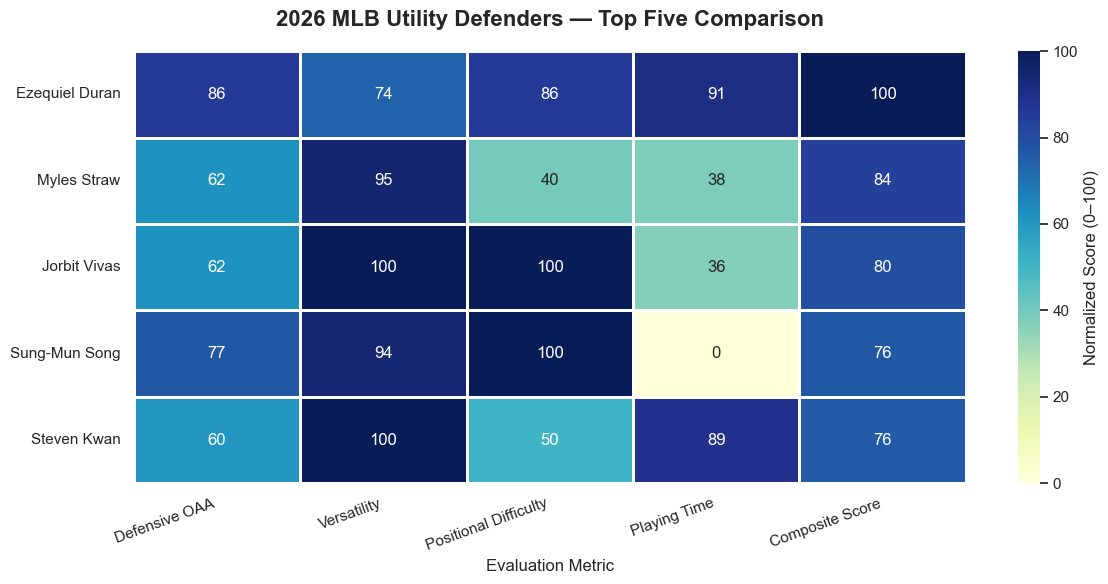

Top-five comparison visualization saved!


,Defensive OAA,Versatility,Positional Difficulty,Playing Time,Composite Score
player_name,,,,,
Ezequiel Duran,85.6,73.7,85.7,90.9,100.0
Myles Straw,62.0,95.1,39.7,37.8,83.7
Jorbit Vivas,62.3,100.0,100.0,36.4,79.7
Sung-Mun Song,76.8,94.4,100.0,0.0,76.3
Steven Kwan,60.5,100.0,50.4,89.0,76.0


In [21]:

# Step 63: Top-five utility defender comparison

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

visual_dir = Path("../visuals")
visual_dir.mkdir(parents=True, exist_ok=True)

# Load final rankings
rankings = pd.read_csv(
    "../data/2026_utility_defender_rankings.csv"
)

top5 = rankings.nsmallest(5, "final_rank").copy()

# Metrics for comparison
metrics = {
    "Defensive OAA": "oaa_per_1000_innings",
    "Versatility": "versatility_score",
    "Positional Difficulty": "demanding_position_share",
    "Playing Time": "total_innings",
    "Composite Score": "adjusted_composite_score"
}

# Normalize metrics across all 89 eligible players
comparison = pd.DataFrame(
    index=top5["player_name"]
)

for label, column in metrics.items():
    values = pd.to_numeric(rankings[column], errors="coerce")
    minimum = values.min()
    maximum = values.max()

    if maximum > minimum:
        normalized = (
            (pd.to_numeric(top5[column], errors="coerce") - minimum)
            / (maximum - minimum)
        ) * 100
    else:
        normalized = pd.Series(50.0, index=top5.index)

    comparison[label] = normalized.to_numpy()

# Create heatmap
fig, ax = plt.subplots(figsize=(12, 6))

sns.heatmap(
    comparison,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    linewidths=0.8,
    cbar_kws={"label": "Normalized Score (0–100)"},
    ax=ax
)

ax.set_title(
    "2026 MLB Utility Defenders — Top Five Comparison",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Evaluation Metric")
ax.set_ylabel("")
plt.xticks(rotation=20, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    visual_dir / "top5_defensive_comparison_2026.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Top-five comparison visualization saved!")
display(comparison.round(1))


In [22]:

# Step 64: Audit defensive performance in the top 20

import pandas as pd

rankings = pd.read_csv(
    "../data/2026_utility_defender_rankings.csv"
)

top20 = rankings.nsmallest(20, "final_rank").copy()

audit_columns = [
    "final_rank",
    "player_name",
    "adjusted_composite_score",
    "outs_above_average",
    "oaa_per_1000_innings",
    "versatility_score",
    "meaningful_positions",
    "total_innings"
]

display(top20[audit_columns].round(2))

negative_oaa = top20[
    top20["oaa_per_1000_innings"] < 0
]

print("Top-20 players with negative defensive OAA rate:")
display(negative_oaa[audit_columns].round(2))

print(
    "Percentage of top-20 players with negative OAA rate:",
    f"{len(negative_oaa) / len(top20) * 100:.1f}%"
)


,final_rank,player_name,adjusted_composite_score,outs_above_average,oaa_per_1000_innings,versatility_score,meaningful_positions,total_innings
0,1,Ezequiel Duran,76.93,17.0,13.26,0.84,3,1282.33
1,2,Myles Straw,67.81,4.0,5.26,0.97,3,760.67
2,3,Jorbit Vivas,65.51,4.0,5.35,1.00,2,747.33
3,4,Sung-Mun Song,63.64,4.0,10.27,0.97,2,389.33
4,5,Steven Kwan,63.47,6.0,4.75,1.00,2,1263.67
5,6,Brice Matthews,63.19,6.0,11.30,0.79,3,531.00
6,7,Bryson Stott,62.45,9.0,6.81,0.85,2,1321.00
7,8,Nico Hoerner,62.26,11.0,8.02,0.82,2,1372.00
8,9,Jake Mangum,61.41,-1.0,-1.01,0.92,3,986.33
9,10,Kevin McGonigle,61.26,-3.0,-2.27,1.00,2,1319.67


Top-20 players with negative defensive OAA rate:


,final_rank,player_name,adjusted_composite_score,outs_above_average,oaa_per_1000_innings,versatility_score,meaningful_positions,total_innings
8,9,Jake Mangum,61.41,-1.0,-1.01,0.92,3,986.33
9,10,Kevin McGonigle,61.26,-3.0,-2.27,1.00,2,1319.67
15,16,Esteury Ruiz,59.10,-1.0,-1.73,0.96,3,578.67
16,17,Spencer Steer,59.05,-2.0,-2.46,0.80,4,812.00


Percentage of top-20 players with negative OAA rate: 20.0%


In [23]:

# Step 65: Compare original rankings with positive-OAA eligibility

import pandas as pd

rankings = pd.read_csv(
    "../data/2026_utility_defender_rankings.csv"
)

# Preserve the original ranking
original_top20 = rankings.nsmallest(20, "final_rank").copy()

# Alternative: require positive defensive performance
positive_defense = rankings[
    rankings["oaa_per_1000_innings"] > 0
].copy()

positive_defense = positive_defense.sort_values(
    "adjusted_composite_score",
    ascending=False
).reset_index(drop=True)

positive_defense["positive_oaa_rank"] = (
    positive_defense.index + 1
)

# Compare the two top-20 groups
original_ids = set(original_top20["player_id"])

filtered_top20 = positive_defense.head(20)
filtered_ids = set(filtered_top20["player_id"])

new_entries = filtered_top20[
    ~filtered_top20["player_id"].isin(original_ids)
]

print("Original top 20:")
display(original_top20[
    ["final_rank", "player_name",
     "oaa_per_1000_innings"]
])

print("\nPositive-OAA top 20:")
display(filtered_top20[
    ["positive_oaa_rank", "player_name",
     "oaa_per_1000_innings"]
])

print("\nNew players entering the top 20:")
display(new_entries[
    ["positive_oaa_rank", "player_name",
     "oaa_per_1000_innings"]
])

print(
    "\nTop-20 overlap:",
    len(original_ids & filtered_ids),
    "of 20"
)

print(
    "Eligible positive-OAA players:",
    len(positive_defense)
)


Original top 20:


,final_rank,player_name,oaa_per_1000_innings
0,1,Ezequiel Duran,13.257083
1,2,Myles Straw,5.258545
2,3,Jorbit Vivas,5.352364
3,4,Sung-Mun Song,10.273973
4,5,Steven Kwan,4.748088
5,6,Brice Matthews,11.299435
6,7,Bryson Stott,6.813020
7,8,Nico Hoerner,8.017493
8,9,Jake Mangum,-1.013856
9,10,Kevin McGonigle,-2.273301



Positive-OAA top 20:


,positive_oaa_rank,player_name,oaa_per_1000_innings
0,1,Ezequiel Duran,13.257083
1,2,Myles Straw,5.258545
2,3,Jorbit Vivas,5.352364
3,4,Sung-Mun Song,10.273973
4,5,Steven Kwan,4.748088
5,6,Brice Matthews,11.299435
6,7,Bryson Stott,6.813020
7,8,Nico Hoerner,8.017493
8,9,Zach McKinstry,8.374040
9,10,Josh Lowe,2.546689



New players entering the top 20:


,positive_oaa_rank,player_name,oaa_per_1000_innings
16,17,Kody Clemens,0.824856
17,18,Mauricio Dubón,4.528302
18,19,Jonny DeLuca,17.789072
19,20,Fernando Tatis Jr.,2.978407



Top-20 overlap: 16 of 20
Eligible positive-OAA players: 39


In [24]:

# Step 66: Export positive-OAA rankings and comparison

from pathlib import Path
import pandas as pd

data_dir = Path("../data")
data_dir.mkdir(parents=True, exist_ok=True)

# Export alternative rankings
positive_defense.to_csv(
    data_dir / "2026_positive_oaa_rankings.csv",
    index=False
)

# Compare original and alternative top 20
original_comparison = original_top20[
    ["player_id", "player_name", "final_rank"]
].copy()

alternative_comparison = filtered_top20[
    ["player_id", "positive_oaa_rank"]
].copy()

comparison = original_comparison.merge(
    alternative_comparison,
    on="player_id",
    how="outer"
)

comparison["original_top20"] = (
    comparison["final_rank"].notna()
)

comparison["positive_oaa_top20"] = (
    comparison["positive_oaa_rank"].notna()
)

comparison["status"] = comparison.apply(
    lambda row:
        "Retained" if row["original_top20"]
        and row["positive_oaa_top20"]
        else "Removed" if row["original_top20"]
        else "Added",
    axis=1
)

comparison.to_csv(
    data_dir / "2026_oaa_eligibility_comparison.csv",
    index=False
)

print("Alternative rankings exported successfully!")
print("\nTop-20 comparison:")
display(comparison.sort_values(
    ["positive_oaa_rank", "final_rank"],
    na_position="last"
))


Alternative rankings exported successfully!

Top-20 comparison:


,player_id,player_name,final_rank,positive_oaa_rank,original_top20,positive_oaa_top20,status
15,677649,Ezequiel Duran,1.0,1.0,True,True,Retained
5,664702,Myles Straw,2.0,2.0,True,True,Retained
16,678391,Jorbit Vivas,3.0,3.0,True,True,Retained
23,823550,Sung-Mun Song,4.0,4.0,True,True,Retained
17,680757,Steven Kwan,5.0,5.0,True,True,Retained
20,694728,Brice Matthews,6.0,6.0,True,True,Retained
18,681082,Bryson Stott,7.0,7.0,True,True,Retained
3,663538,Nico Hoerner,8.0,8.0,True,True,Retained
2,656716,Zach McKinstry,11.0,9.0,True,True,Retained
10,666139,Josh Lowe,12.0,10.0,True,True,Retained


In [25]:

# Step 67: Final data quality audit

import pandas as pd
import numpy as np

rankings = pd.read_csv(
    "../data/2026_utility_defender_rankings.csv"
)

print("2026 MLB UTILITY DEFENDER DATA AUDIT")
print("=" * 45)

# 1. Dataset size
print("\nTotal players:", len(rankings))

# 2. Duplicate player IDs
duplicates = rankings["player_id"].duplicated().sum()
print("Duplicate player IDs:", duplicates)

# 3. Missing values
important_columns = [
    "player_id",
    "player_name",
    "total_innings",
    "outs_above_average",
    "oaa_per_1000_innings",
    "versatility_score",
    "adjusted_composite_score"
]

missing = rankings[important_columns].isna().sum()

print("\nMissing values:")
display(missing.to_frame("missing_count"))

# 4. Invalid playing time
invalid_innings = rankings[
    rankings["total_innings"] <= 0
]

print("\nPlayers with invalid innings:", len(invalid_innings))

# 5. Validate OAA rate calculation
rankings["recalculated_oaa_rate"] = (
    rankings["outs_above_average"]
    / rankings["total_innings"]
    * 1000
)

rankings["oaa_rate_difference"] = (
    rankings["recalculated_oaa_rate"]
    - rankings["oaa_per_1000_innings"]
).abs()

rate_errors = rankings[
    rankings["oaa_rate_difference"] > 0.01
]

print("OAA rate inconsistencies:", len(rate_errors))

# 6. Check score ranges
invalid_scores = rankings[
    ~rankings["adjusted_composite_score"].between(0, 100)
]

print("Composite scores outside 0–100:", len(invalid_scores))

# 7. Summary
checks = {
    "Duplicate player IDs": duplicates == 0,
    "Missing required values": missing.sum() == 0,
    "Positive defensive innings": len(invalid_innings) == 0,
    "OAA rate consistency": len(rate_errors) == 0,
    "Composite score range": len(invalid_scores) == 0
}

print("\nFINAL AUDIT RESULTS")
print("=" * 45)

for check, passed in checks.items():
    print(f"{check}: {'PASS' if passed else 'REVIEW'}")

print(
    "\nOverall internal audit:",
    "PASS" if all(checks.values()) else "REVIEW REQUIRED"
)


2026 MLB UTILITY DEFENDER DATA AUDIT

Total players: 89
Duplicate player IDs: 0

Missing values:


,missing_count
player_id,0
player_name,0
total_innings,0
outs_above_average,0
oaa_per_1000_innings,0
versatility_score,0
adjusted_composite_score,0



Players with invalid innings: 0
OAA rate inconsistencies: 0
Composite scores outside 0–100: 0

FINAL AUDIT RESULTS
Duplicate player IDs: PASS
Missing required values: PASS
Positive defensive innings: PASS
OAA rate consistency: PASS
Composite score range: PASS

Overall internal audit: PASS
